# 01 · Exploratory data analysis: Walmart M5 sales

**Goal:** understand the data before computing any metric: its grain, coverage, quality and the patterns that should shape the analysis.
Each section ends with a short *so what*. The findings log at the bottom lists the questions the main analysis answers.

Data: real Walmart daily unit sales and weekly shelf prices for 3,049 products in 10 stores (CA, TX, WI), Jan 2011 – May 2016, released for the M5 forecasting competition (University of Nicosia / Kaggle). Product names are anonymized; category, department, store and state are real.

In [1]:
%matplotlib inline
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
from retailrev.paths import connect
from retailrev import figures as F   # shared chart style + palette
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
con = connect()
q = lambda sql: con.execute(sql).df()

## 1. Grain and coverage

In [2]:
q('''
SELECT 'daily sales rows (item x store x day)' AS table_name, count(*) AS n_rows FROM stg_sales_daily
UNION ALL SELECT 'price rows (item x store x week)', count(*) FROM stg_prices
UNION ALL SELECT 'items', count(*) FROM dim_item
UNION ALL SELECT 'stores', count(*) FROM dim_store
UNION ALL SELECT 'days', count(*) FROM stg_calendar
''')

,table_name,n_rows
0,daily sales rows (item x store x day),59181090
1,price rows (item x store x week),6841121
2,items,3049
3,stores,10
4,days,1941


In [3]:
q('''
SELECT cat_id, count(DISTINCT dept_id) AS departments, count(*) AS items
FROM dim_item GROUP BY 1 ORDER BY items DESC
''')

,cat_id,departments,items
0,FOODS,3,1437
1,HOUSEHOLD,2,1047
2,HOBBIES,2,565


In [4]:
q('''
SELECT fiscal_year, min(date) AS first_day, max(date) AS last_day, count(*) AS n_days,
       max(fiscal_week) AS fiscal_weeks
FROM stg_calendar GROUP BY 1 ORDER BY 1
''')

,fiscal_year,first_day,last_day,n_days,fiscal_weeks
0,2012,2011-01-29,2012-01-27,364,52
1,2013,2012-01-28,2013-01-25,364,52
2,2014,2013-01-26,2014-01-31,371,53
3,2015,2014-02-01,2015-01-30,364,52
4,2016,2015-01-31,2016-01-29,364,52
5,2017,2016-01-30,2016-05-22,114,17


**So what:** the data follows Walmart's fiscal calendar (Saturday–Friday weeks, years ending late January).
FY2014 has **53 weeks**, so a naive year-over-year comparison overstates FY2014 growth and understates FY2015. All growth metrics use a 52-week basis.
FY2017 is a partial year (16 full weeks): it is used only for year-to-date tracking.

## 2. Data quality

In [5]:
from retailrev.quality import run_checks
run_checks()[["check", "type", "value", "expectation", "passed"]]

,check,type,value,expectation,passed
0,Units reconcile: raw daily = weekly fact,hard,0.000,== 0,True
1,Revenue reconciles: weekly fact = daily store-...,hard,0.000,< 0.01,True
2,Sales on days with no shelf price,hard,0.000,== 0,True
3,Negative unit values,hard,0.000,== 0,True
4,Duplicate store-item-week price rows,hard,0.000,== 0,True
5,Days with near-zero chain sales (store closures),finding,5.000,== 5,True
6,53-week fiscal years,finding,1.000,== 1,True
7,Implausible prices (<= $0.05),finding,105.000,> 0,True
8,Store-items added to the assortment after FY2012,finding,"13,454.000",> 0,True
9,Listed full weeks with zero sales,finding,23.900,> 0,True


**So what:** units and revenue reconcile exactly across every table, and every unit sold has a shelf price, so `revenue = units × price` is complete.
Five days have near-zero sales chain-wide: all are Christmas Day (stores closed). These are excluded from event baselines.

## 3. How sparse is item-level demand?

Share of listed item-store-weeks with zero sales: 23.2%
Median weekly units: 3   90th pct: 20   max: 1,141


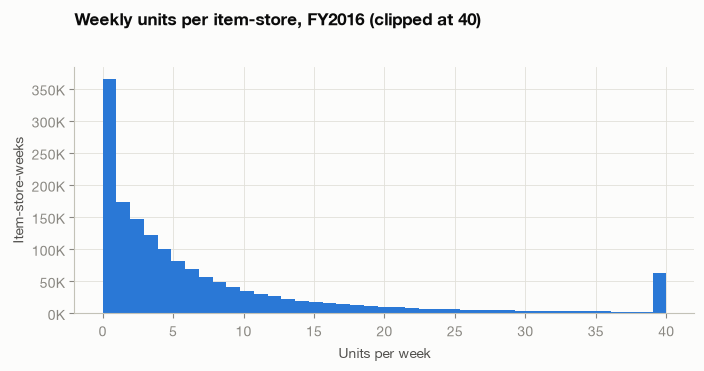

In [6]:
d = q('''
SELECT units FROM fct_item_store_week WHERE days_observed = 7 AND fiscal_year = 2016
''')
print(f"Share of listed item-store-weeks with zero sales: {(d.units == 0).mean():.1%}")
print(f"Median weekly units: {d.units.median():.0f}   90th pct: {d.units.quantile(.9):.0f}   max: {d.units.max():,.0f}")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(d.units.clip(upper=40), bins=41, color=F.BLUE)
ax.set_title("Weekly units per item-store, FY2016 (clipped at 40)")
ax.set_xlabel("Units per week"); ax.set_ylabel("Item-store-weeks")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e3:.0f}K"))
plt.show()

**So what:** demand is intermittent: about a quarter of listed weeks sell nothing, and the median item sells a handful of units a week.
Any model on `log(units)` needs care with zeros, and its results should be checked on faster-moving items (done in the pricing analysis).

## 4. Where does revenue come from?

In [7]:
q('''
SELECT cat_id, dept_id, sum(revenue) AS revenue_fy2016,
       sum(revenue) / sum(sum(revenue)) OVER () AS share,
       sum(revenue) / sum(units) AS avg_unit_price,
       count(DISTINCT item_id) AS items
FROM fct_item_store_week WHERE fiscal_year = 2016
GROUP BY ALL ORDER BY revenue_fy2016 DESC
''')

,cat_id,dept_id,revenue_fy2016,share,avg_unit_price,items
0,FOODS,FOODS_3,"14,617,305.990",0.342,2.350,823
1,HOUSEHOLD,HOUSEHOLD_1,"10,068,960.600",0.235,3.646,532
2,FOODS,FOODS_2,"6,018,791.780",0.141,3.456,398
3,HOBBIES,HOBBIES_1,"5,656,894.630",0.132,4.498,416
4,HOUSEHOLD,HOUSEHOLD_2,"3,191,009.770",0.075,4.774,515
5,FOODS,FOODS_1,"2,928,011.390",0.068,2.679,216
6,HOBBIES,HOBBIES_2,"299,193.230",0.007,2.108,149


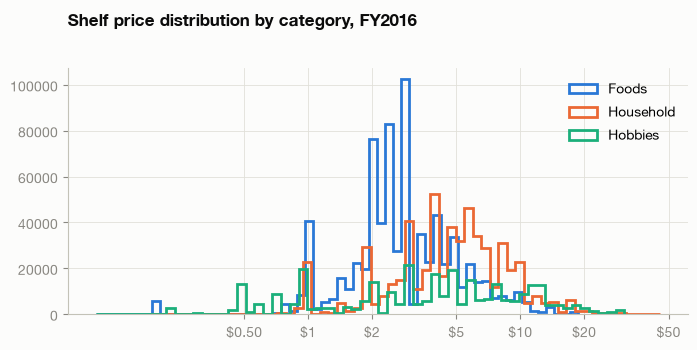

In [8]:
p = q("SELECT sell_price, cat_id FROM stg_prices p JOIN dim_item USING (item_id) WHERE wm_yr_wk BETWEEN 11501 AND 11552")
fig, ax = plt.subplots(figsize=(8, 3.2))
for cat in ["FOODS", "HOUSEHOLD", "HOBBIES"]:
    v = np.log10(p.loc[p.cat_id == cat, "sell_price"].astype(float).clip(lower=0.1))
    ax.hist(v, bins=60, histtype="step", lw=2, color=F.CAT_COLORS[cat], label=cat.title())
ax.set_xticks(np.log10([0.5, 1, 2, 5, 10, 20, 50]), ["$0.50", "$1", "$2", "$5", "$10", "$20", "$50"])
ax.set_title("Shelf price distribution by category, FY2016"); ax.legend()
plt.show()

**So what:** FOODS is 55% of revenue from cheap, high-frequency items (~$3 average); FOODS_3 alone is the largest department.
HOUSEHOLD and HOBBIES sell fewer units at higher prices, so a few items can move their totals a lot.

## 5. Trend and assortment growth

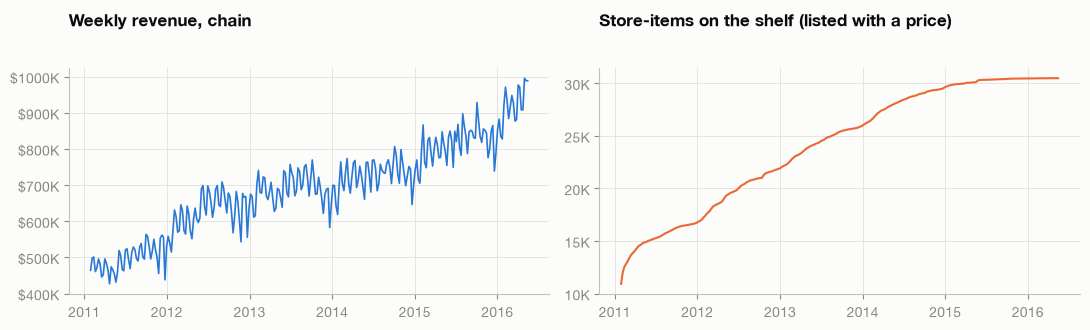

In [9]:
w = q('''
SELECT week_start, sum(revenue) AS revenue, count(*) AS store_items_listed
FROM fct_item_store_week WHERE days_observed = 7
GROUP BY week_start ORDER BY week_start
''')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(w.week_start, w.revenue, color=F.BLUE, lw=1.2)
axes[0].set_title("Weekly revenue, chain")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1e3:.0f}K"))
axes[1].plot(w.week_start, w.store_items_listed, color=F.ORANGE, lw=1.5)
axes[1].set_title("Store-items on the shelf (listed with a price)")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e3:.0f}K"))
plt.tight_layout(); plt.show()

**So what:** the number of store-items on the shelf rose from about 17K to 30K between 2011 and 2015.
Revenue growth therefore mixes two things: existing products selling more, and new products being added.
These have to be separated, using **comparable (like-for-like) sales** and a revenue bridge.

One caveat: M5 contains only items still sold in 2016, so products discontinued earlier are missing. That also inflates early-period growth, and it's another reason to rely on comparable sales.

## 6. Store-level shifts

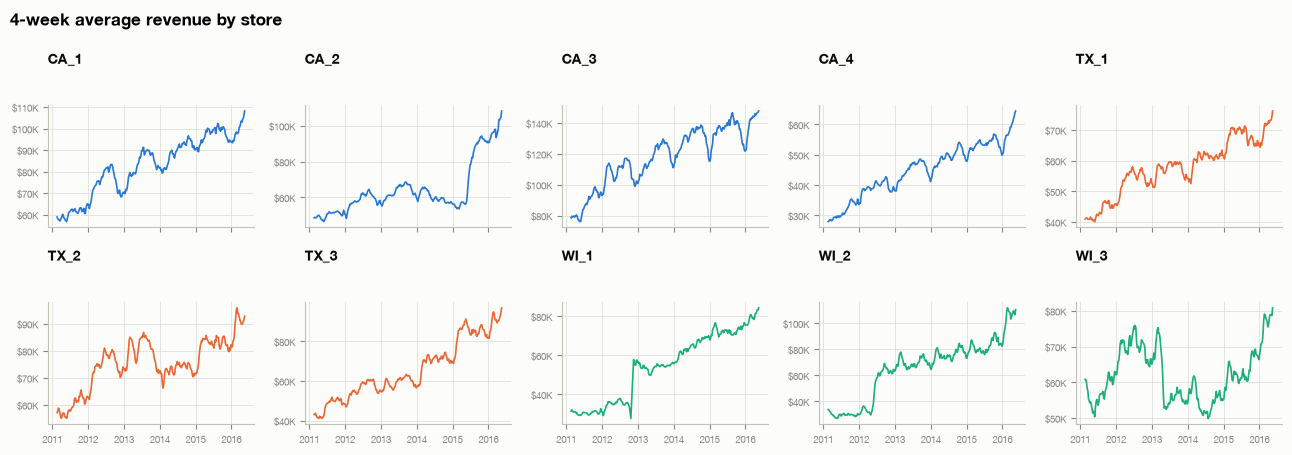

In [10]:
s = q('''
SELECT week_start, store_id, sum(revenue) AS revenue
FROM fct_item_store_week WHERE days_observed = 7 GROUP BY ALL ORDER BY week_start
''').pivot(index="week_start", columns="store_id", values="revenue")
fig, axes = plt.subplots(2, 5, figsize=(13, 4.6), sharex=True)
for ax, store in zip(axes.flat, s.columns):
    ax.plot(s.index, s[store].rolling(4).mean(), color=F.STATE_COLORS[store[:2]], lw=1.2)
    ax.set_title(store, fontsize=10); ax.tick_params(labelsize=7)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1e3:.0f}K"))
plt.suptitle("4-week average revenue by store", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

In [11]:
# Flag sustained step changes: 4-week average vs the 4 weeks before
roll = s.rolling(4).mean()
chg = roll / roll.shift(4) - 1
breaks = chg[chg.abs() > 0.25].stack().dropna().rename("change_vs_prior_4wk").reset_index()
breaks.groupby("store_id").agg(first_week=("week_start", "min"), peak_change=("change_vs_prior_4wk", "max"))

,first_week,peak_change
store_id,,
CA_2,2015-06-13,0.296
WI_1,2012-11-03,1.088
WI_2,2012-05-26,0.587


**So what:** WI_2 (mid-2012) and WI_1 (late 2012) step up by 30–100% and stay higher. CA_2 jumps by about 30% in mid-2015.
These look like remodels or format changes. The data doesn't say what caused them, so store comparisons rely on comp growth and flag these stores rather than explaining them.

## 7. Calendar rhythm

In [12]:
wd = pd.read_csv("../outputs/weekday_profile.csv").set_index("weekday")
wd.style.format("{:.2f}").background_gradient(cmap="Blues", axis=None)

,FOODS,HOBBIES,HOUSEHOLD
weekday,,,
Monday,0.97,0.94,0.94
Tuesday,0.90,0.88,0.86
Wednesday,0.88,0.89,0.84
Thursday,0.88,0.89,0.85
Friday,0.98,1.03,1.00
Saturday,1.18,1.21,1.26
Sunday,1.21,1.16,1.25


In [13]:
q('''
SELECT calendar_month AS month, sum(revenue) / count(DISTINCT c.date) AS revenue_per_day
FROM fct_store_dept_day d JOIN stg_calendar c USING (date)
WHERE c.fiscal_year BETWEEN 2014 AND 2016 AND NOT (calendar_month = 12 AND extract(day FROM c.date) = 25)
GROUP BY 1 ORDER BY 1
''').assign(index_vs_avg=lambda d: d.revenue_per_day / d.revenue_per_day.mean())

,month,revenue_per_day,index_vs_avg
0,1,"105,423.435",0.984
1,2,"104,933.962",0.980
2,3,"105,783.503",0.988
3,4,"104,085.778",0.972
4,5,"104,444.588",0.975
5,6,"107,094.725",1.000
6,7,"107,743.404",1.006
7,8,"110,873.093",1.035
8,9,"109,336.790",1.021
9,10,"110,977.988",1.036


**So what:** weekends run about 20% above average and midweek about 12% below, so any day-level comparison must match weekdays.
Monthly seasonality is mild compared with the long-run trend: this is everyday grocery and household spending, not a holiday-driven business.

## 8. Pricing behaviour

In [14]:
pm = pd.read_csv("../outputs/price_moves.csv")
pm.groupby("dept_id")[["price_increases", "price_decreases", "listed_weeks"]].sum().assign(
    changes_per_100_weeks=lambda d: 100 * (d.price_increases + d.price_decreases) / d.listed_weeks)

,price_increases,price_decreases,listed_weeks,changes_per_100_weeks
dept_id,,,,
FOODS_1,5707,2059,475694,1.633
FOODS_2,8912,7047,735745,2.169
FOODS_3,13873,9968,1654127,1.441
HOBBIES_1,4212,2980,868812,0.828
HOBBIES_2,1002,687,290787,0.581
HOUSEHOLD_1,4695,4695,1043272,0.900
HOUSEHOLD_2,3636,3434,1101830,0.642


**So what:** prices change rarely (about 1–2 times per 100 item-weeks), and increases outnumber decreases in most departments.
That gives enough within-item price variation to estimate elasticities, with item and store-week fixed effects absorbing everything else.

## Findings log → questions for the analysis

| # | Exploration finding | Question it raises | Where it's answered |
|---|---|---|---|
| 1 | Assortment grew ~79% (17K → 30K store-items) | How much growth is real like-for-like demand, and why did it fall? | `comp_sales.sql`, `pvm_bridge.sql`; `drivers.py` (cannibalization, cohorts, timing); `robustness.py` |
| 2 | FY2014 has 53 weeks | Is reported FY2014 growth inflated? | `annual_revenue.sql` (52-week basis) |
| 3 | Average unit price rose 2.69 → 3.08 | Is that price increases, mix, or inflation? | Revenue bridge (price vs mix); `inflation.py` (BLS CPI) |
| 4 | Revenue is concentrated in a subset of items | How long is the tail, which products behave alike, and who are the best sellers? | `item_pareto.sql`, `item_growth.sql`, `segments.py` (five product segments) |
| 5 | Three stores show step changes | How big were they, and which stores truly outperform? | `store_events.py` (changepoints + synthetic control); `store_scorecard.sql` |
| 6 | Strong weekday rhythm; Christmas closures | What do holidays and events actually do to sales? | `events.py` (same-weekday baselines) |
| 7 | SNAP days vary by state | How much do benefit days lift food revenue, and when? | `events.py` (SNAP lift + day-of-month timing) |
| 8 | Sparse demand; prices change rarely | How price-sensitive is each department, and how would we test it? | `pricing.py` (Poisson FE), `price_events.py` (event study), `experiment_design.py` (power) |
| 9 | ~24% of listed weeks sell nothing | How much revenue is lost to stock-outs? | `sql/03_stockouts.sql`, `stockouts.py` |
| 10 | New products enter all year | How fast do launches ramp and roll out? | `launches.py` |
